In [1]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import KFold, cross_val_score
import sklearn.metrics as metrics
import pandas as pd
import matplotlib.pyplot as plt
import os
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm

# Korpus aufbauen

In [2]:
corpus = []      # texts
file_names = []  # file name of every text, in the same order

data_folder = os.path.join(os.getcwd(), "..", "data", "corpus")
for file in sorted(os.listdir(data_folder)):  # sorted: same order on every computer
    with open(os.path.join(data_folder, file), encoding="utf8") as f:
        corpus.append(f.read())
    file_names.append(file)

print(len(corpus), "Texte wurden erfolgreich in den Korpus geladen.")

36 Texte wurden erfolgreich in den Korpus geladen.


In [3]:
corpus_list = [] #initial empty list / reset already existing list
corpus_name = [] #initial empty list / reset already existing list

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 * asw)
    
    return round(fre,2)

dic = pyphen.Pyphen(lang="de_DE")

def syllables(word):
    """Silben eines einzelnen Wortes."""
    return len(dic.inserted(word).split("-"))

def avg_syllables_per_word(text):
    words = re.findall(r"\b\w+\b", text.lower())
    return round(sum(syllables(w) for w in words) / len(words), 1)

def wiener_sachtext_formel(text):
    words = re.findall(r"\b\w+\b", text.lower())
    n = len(words)
    syl = [syllables(w) for w in words]            # Silben pro Wort

    ms = sum(s >= 3 for s in syl) / n * 100        # % Wörter mit 3 oder mehr Silben
    sl = avg_sen_len(text)                         # Wörter pro Satz
    iw = sum(len(w) > 6 for w in words) / n * 100  # % Wörter mit mehr als 6 Buchstaben
    es = sum(s == 1 for s in syl) / n * 100        # % einsilbige Wörter

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf, 2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [4]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [5]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 2 → [1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0]
Vektor für Text 3 → [1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

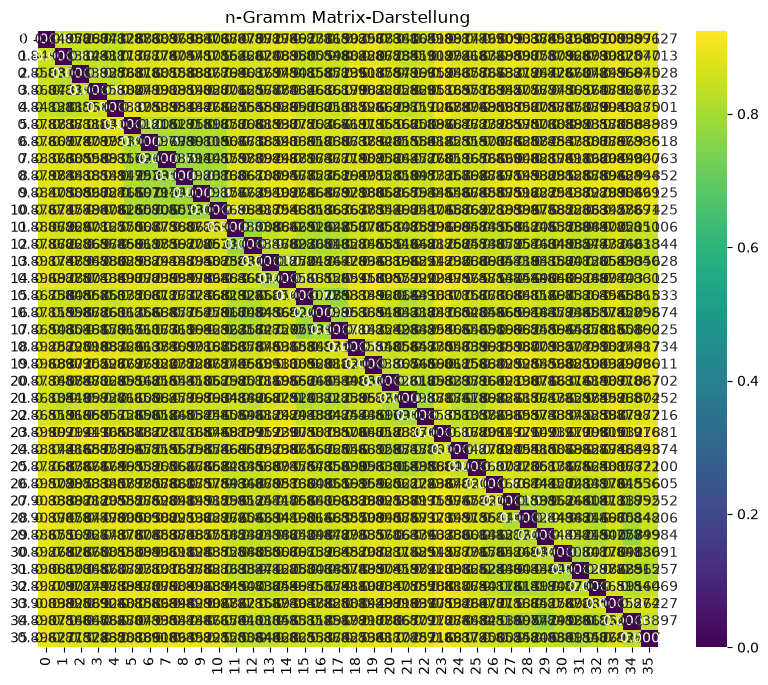

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [7]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)

    avgsenlen = avg_sen_len(text) #average sentence length
    avgwordlen = avg_word_len(text)

    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3))
    #print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

5.8 15.7 1.9 9.1 53.15 0.21 0.013 0.003 0.036 0.061 0.005 0.003
-----------------------------------------------
5.5 13.2 1.8 7.18 61.5 0.17 0.022 0.007 0.032 0.062 0.001 0.002
-----------------------------------------------
5.5 17.8 1.8 8.13 56.9 0.16 0.018 0.004 0.024 0.07 0.002 0.004
-----------------------------------------------
5.3 16.3 1.7 6.91 64.25 0.17 0.017 0.004 0.03 0.066 0.004 0.004
-----------------------------------------------
5.5 12.7 1.8 7.49 62.0 0.15 0.032 0.005 0.029 0.063 0.002 0.005
-----------------------------------------------
5.4 16.4 1.7 7.33 64.15 0.21 0.004 0.002 0.042 0.088 0.0 0.0
-----------------------------------------------
5.3 13.5 1.8 6.98 61.2 0.2 0.001 0.003 0.05 0.074 0.0 0.0
-----------------------------------------------
5.4 15.5 1.8 7.85 59.2 0.2 0.001 0.002 0.048 0.075 0.0 0.0
-----------------------------------------------
5.4 15.1 1.8 7.58 59.6 0.21 0.001 0.001 0.051 0.072 0.0 0.0
-----------------------------------------------
5.5 13.6 1.

In [8]:
corpus_list

[[5.8, 15.7, 1.9, 9.1, 53.15, 0.21, 0.013, 0.003, 0.036, 0.061, 0.005, 0.003],
 [5.5, 13.2, 1.8, 7.18, 61.5, 0.17, 0.022, 0.007, 0.032, 0.062, 0.001, 0.002],
 [5.5, 17.8, 1.8, 8.13, 56.9, 0.16, 0.018, 0.004, 0.024, 0.07, 0.002, 0.004],
 [5.3, 16.3, 1.7, 6.91, 64.25, 0.17, 0.017, 0.004, 0.03, 0.066, 0.004, 0.004],
 [5.5, 12.7, 1.8, 7.49, 62.0, 0.15, 0.032, 0.005, 0.029, 0.063, 0.002, 0.005],
 [5.4, 16.4, 1.7, 7.33, 64.15, 0.21, 0.004, 0.002, 0.042, 0.088, 0.0, 0.0],
 [5.3, 13.5, 1.8, 6.98, 61.2, 0.2, 0.001, 0.003, 0.05, 0.074, 0.0, 0.0],
 [5.4, 15.5, 1.8, 7.85, 59.2, 0.2, 0.001, 0.002, 0.048, 0.075, 0.0, 0.0],
 [5.4, 15.1, 1.8, 7.58, 59.6, 0.21, 0.001, 0.001, 0.051, 0.072, 0.0, 0.0],
 [5.5, 13.6, 1.8, 7.5, 61.1, 0.21, 0.001, 0.001, 0.054, 0.073, 0.0, 0.0],
 [5.4, 12.7, 1.8, 6.92, 62.0, 0.21, 0.001, 0.003, 0.056, 0.074, 0.0, 0.0],
 [4.9, 23.9, 1.6, 6.39, 62.5, 0.19, 0.01, 0.003, 0.023, 0.094, 0.006, 0.003],
 [4.8, 17.2, 1.6, 4.99, 69.2, 0.17, 0.016, 0.005, 0.027, 0.094, 0.005, 0.003],
 [

In [9]:
corpus_vec = np.array(corpus_list)
corpus_matrix = cosine_distances(corpus_vec)

In [10]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 4.12609557e-03, 5.66840380e-04, ...,
        2.62061784e-02, 2.90535281e-02, 2.37706400e-02],
       [4.12609557e-03, 0.00000000e+00, 4.35353436e-03, ...,
        9.58894725e-03, 1.13532767e-02, 8.13029670e-03],
       [5.66840380e-04, 4.35353436e-03, 0.00000000e+00, ...,
        2.59391297e-02, 2.89077426e-02, 2.34882926e-02],
       ...,
       [2.62061784e-02, 9.58894725e-03, 2.59391297e-02, ...,
        0.00000000e+00, 8.67507082e-05, 6.89315972e-05],
       [2.90535281e-02, 1.13532767e-02, 2.89077426e-02, ...,
        8.67507082e-05, 0.00000000e+00, 2.95426304e-04],
       [2.37706400e-02, 8.13029670e-03, 2.34882926e-02, ...,
        6.89315972e-05, 2.95426304e-04, 0.00000000e+00]], shape=(36, 36))

# Heatmap zeichnen

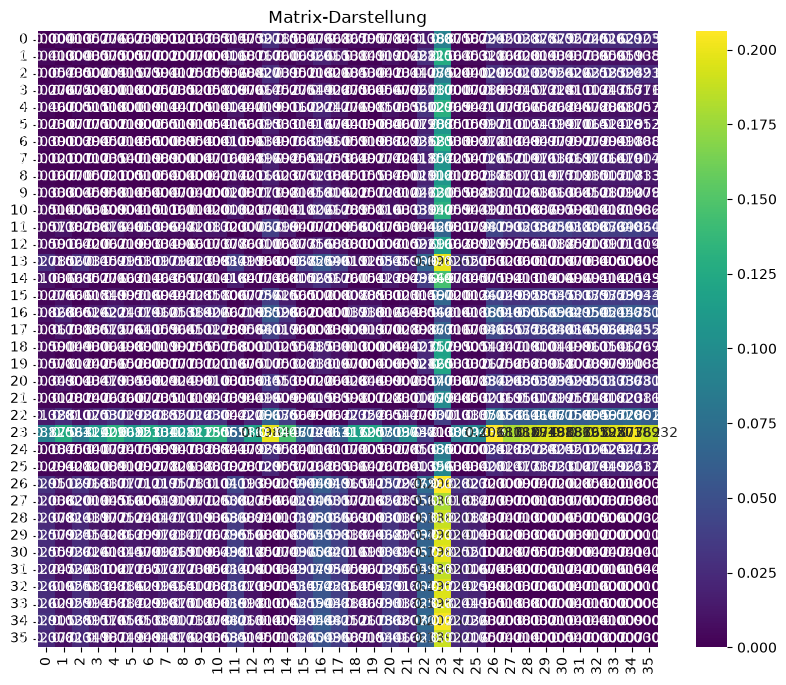

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


-----------------------------------------------------------------

# Decision Tree

In [12]:
colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp["Author"] = [name.split("-")[0].capitalize() for name in file_names]

X = corp[colu] # Features
y = corp.Author # Target variable

In [13]:
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,5.8,15.7,1.9,9.10,53.15,0.21,0.013,0.003,0.036,0.061,0.005,0.003,Achleitner
1,5.5,13.2,1.8,7.18,61.50,0.17,0.022,0.007,0.032,0.062,0.001,0.002,Achleitner
2,5.5,17.8,1.8,8.13,56.90,0.16,0.018,0.004,0.024,0.070,0.002,0.004,Achleitner
3,5.3,16.3,1.7,6.91,64.25,0.17,0.017,0.004,0.030,0.066,0.004,0.004,Achleitner
4,5.5,12.7,1.8,7.49,62.00,0.15,0.032,0.005,0.029,0.063,0.002,0.005,Achleitner
5,5.4,16.4,1.7,7.33,64.15,0.21,0.004,0.002,0.042,0.088,0.000,0.000,Anonymous
6,5.3,13.5,1.8,6.98,61.20,0.20,0.001,0.003,0.050,0.074,0.000,0.000,Anonymous
7,5.4,15.5,1.8,7.85,59.20,0.20,0.001,0.002,0.048,0.075,0.000,0.000,Anonymous
8,5.4,15.1,1.8,7.58,59.60,0.21,0.001,0.001,0.051,0.072,0.000,0.000,Anonymous
9,5.5,13.6,1.8,7.50,61.10,0.21,0.001,0.001,0.054,0.073,0.000,0.000,Anonymous


In [14]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2) # 80% training and 20% test

# Create Decision Tree classifer object
clf = tree.DecisionTreeClassifier(random_state=42)

# Train Decision Tree Classifer
clf_fit = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf_fit.predict(X_test)

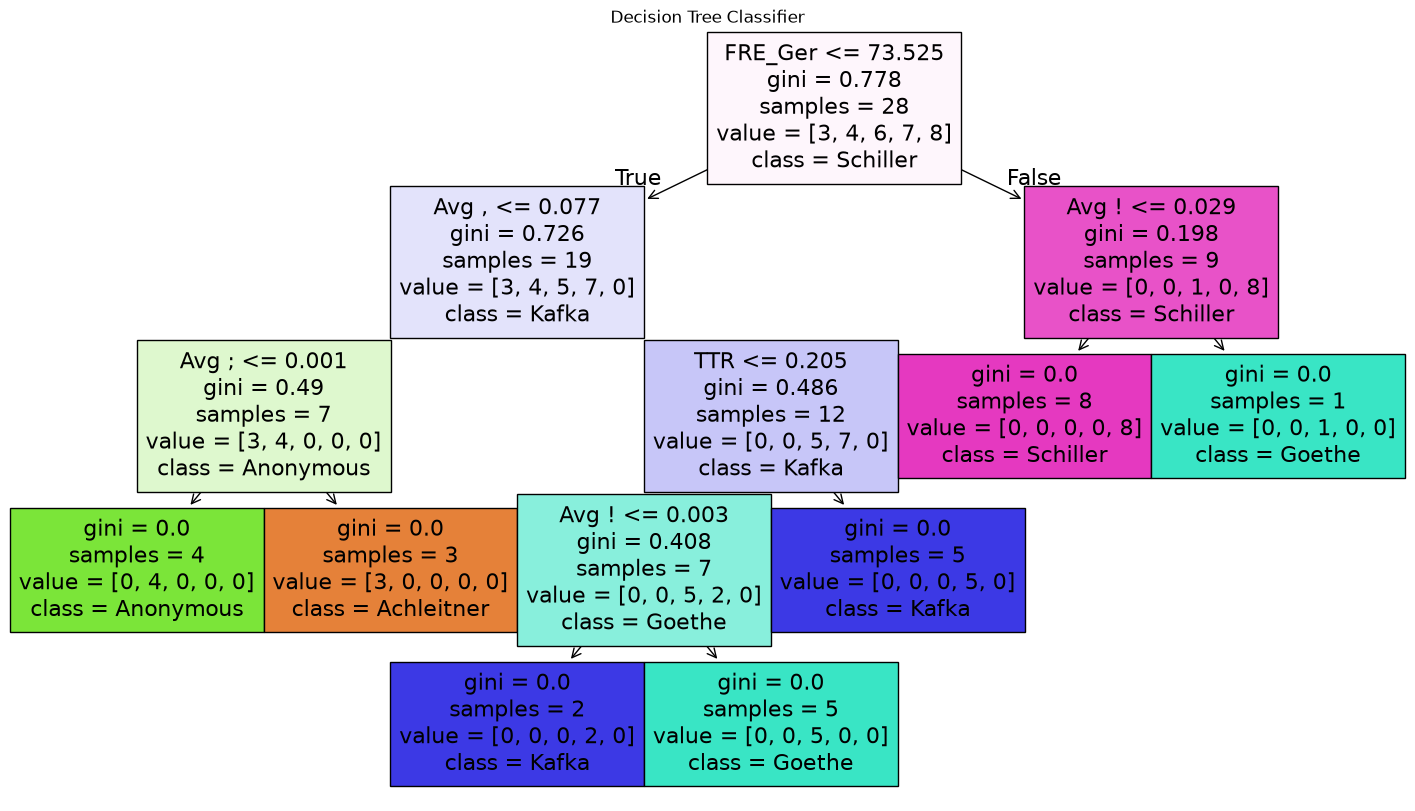

In [15]:
plt.figure(figsize=(18, 10))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Achleitner', 'Anonymous', 'Goethe', 'Kafka', 'Schiller'])
plt.title("Decision Tree Classifier")
plt.show()

In [16]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.75


In [17]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      0.50      0.67         2
      Goethe       0.50      1.00      0.67         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      0.50      0.67         2

    accuracy                           0.75         8
   macro avg       0.80      0.80      0.73         8
weighted avg       0.88      0.75      0.75         8



In [18]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.25       0.75       0.75       0.         0.75       0.25
 0.33333333 1.         0.66666667 0.33333333]
Average CV Score:  0.5083333333333333
Number of CV Scores used in Average:  10


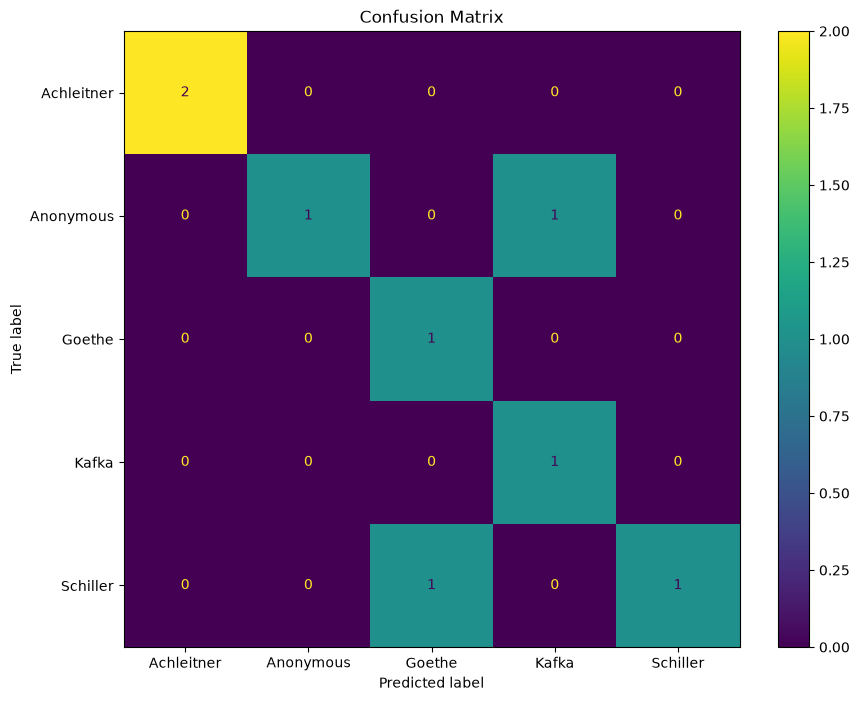

In [19]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [20]:
df_cm_dt = pd.DataFrame()
df_cm_dt["True"] = y_test
df_cm_dt["Predict"] = y_pred
df_cm_dt

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
32,Schiller,Goethe
3,Achleitner,Achleitner


_______________________

# Random Forest

In [21]:
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
class_fit = classifier.fit(X_train, y_train)
y_pred = class_fit.predict(X_test)

In [22]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 87.50%


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      0.50      0.67         2
      Goethe       1.00      1.00      1.00         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      1.00      1.00         2

    accuracy                           0.88         8
   macro avg       0.90      0.90      0.87         8
weighted avg       0.94      0.88      0.88         8



In [24]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.75       1.         0.25       0.5        0.
 0.33333333 1.         1.         1.        ]
Average CV Score:  0.6333333333333333
Number of CV Scores used in Average:  10


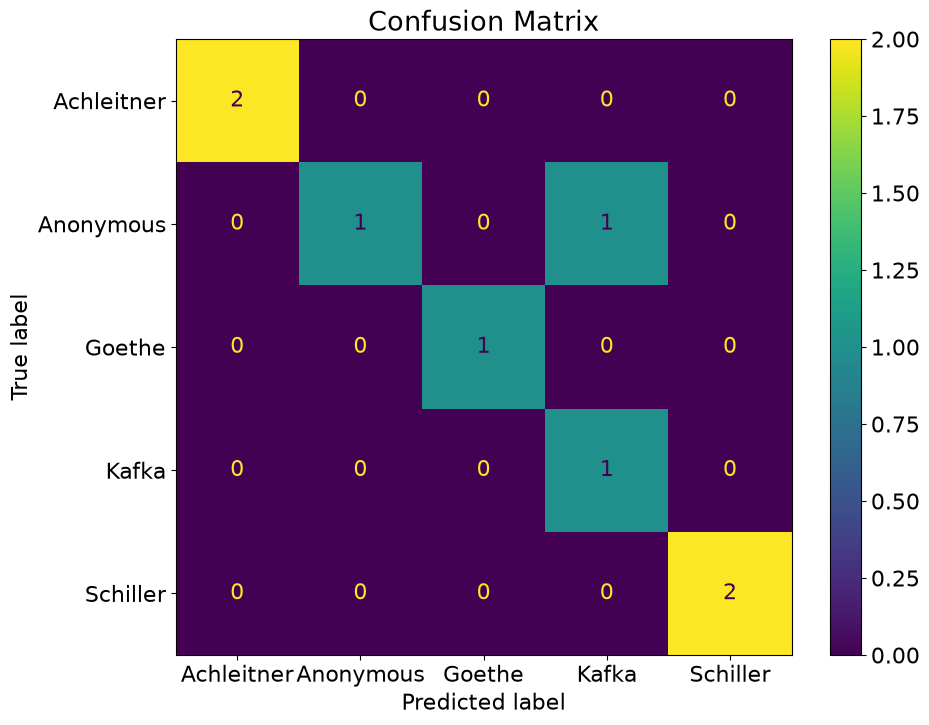

In [25]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [26]:
df_cm_rf = pd.DataFrame()
df_cm_rf["True"] = y_test
df_cm_rf["Predict"] = y_pred
df_cm_rf

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
32,Schiller,Schiller
3,Achleitner,Achleitner


________________________

# Support Vector Machine

In [27]:
#X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=33, test_size=0.2)

clf = svm.SVC(kernel="linear", gamma=1000, C=1000)
clf_fit = clf.fit(X_train, y_train)
clf_fit.score(X_train, y_train)

1.0

In [28]:
y_pred = clf_fit.predict(X_test)

accuracy = metrics.accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 87.50%


In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      1.00      1.00         2
      Goethe       0.50      1.00      0.67         1
       Kafka       1.00      1.00      1.00         1
    Schiller       1.00      0.50      0.67         2

    accuracy                           0.88         8
   macro avg       0.90      0.90      0.87         8
weighted avg       0.94      0.88      0.88         8



In [30]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.75       1.         0.25       0.5        0.
 0.33333333 1.         1.         1.        ]
Average CV Score:  0.6333333333333333
Number of CV Scores used in Average:  10


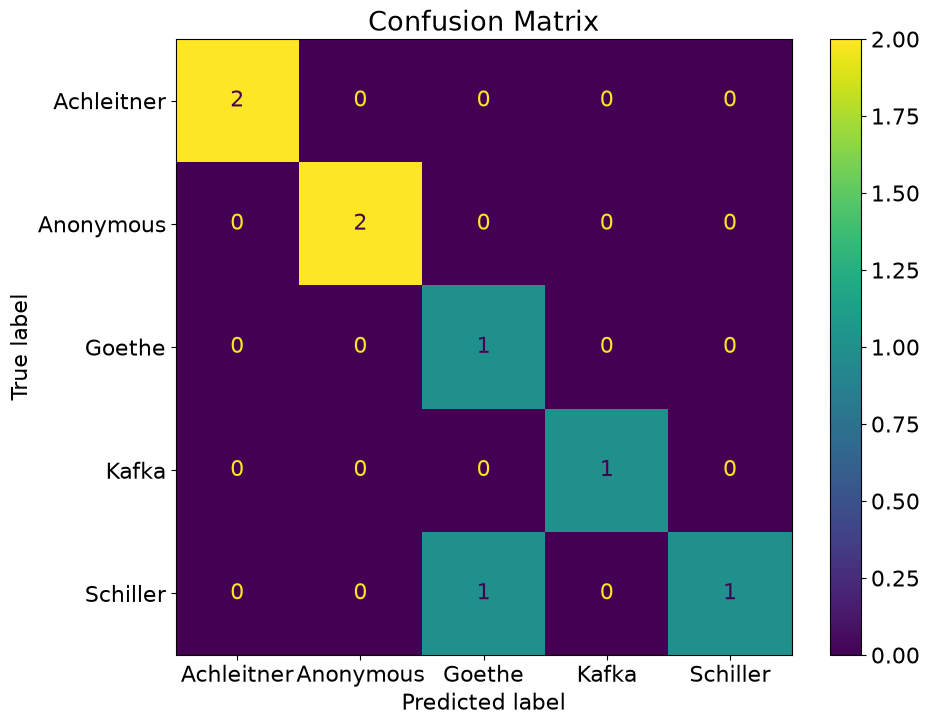

In [31]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [32]:
df_cm_svm = pd.DataFrame()
df_cm_svm["True"] = y_test
df_cm_svm["Predict"] = y_pred
df_cm_svm

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Anonymous
32,Schiller,Goethe
3,Achleitner,Achleitner


------------------

# Predict Ensemble

In [33]:
df_pred_ensemble = pd.DataFrame()
df_pred_ensemble["Decision Tree"] = df_cm_dt["Predict"]
df_pred_ensemble["Random Forest"] = df_cm_rf["Predict"]
df_pred_ensemble["Support Vector Machine"] = df_cm_svm["Predict"]

df_pred_ensemble

,Decision Tree,Random Forest,Support Vector Machine
24,Kafka,Kafka,Kafka
31,Schiller,Schiller,Schiller
2,Achleitner,Achleitner,Achleitner
12,Goethe,Goethe,Goethe
7,Anonymous,Anonymous,Anonymous
5,Kafka,Kafka,Anonymous
32,Goethe,Schiller,Goethe
3,Achleitner,Achleitner,Achleitner


In [34]:
# Funktion zur Ermittlung des Ergebnisnamens
def predEnsemble(row):
    # Wenn Decision Tree und Random Forest übereinstimmen, gib Decision Tree zurück
    if row['Decision Tree'] == row['Random Forest']:
        return row['Decision Tree']
    # Wenn Decision Tree und Support Vector Machine übereinstimmen, gib Decision Tree zurück
    if row['Decision Tree'] == row['Support Vector Machine']:
        return row['Decision Tree']
    # Wenn Random Forest und Support Vector Machine übereinstimmen, gib Random Forest zurück
    if row['Random Forest'] == row['Support Vector Machine']:
        return row['Random Forest']
    # Wenn alle drei unterschiedlich sind, gib Support Vector Machine zurück
    return row['Support Vector Machine']

def colors(row):
    farben = []
    for spalte in ['Decision Tree', 'Random Forest', 'Support Vector Machine']:
        if row[spalte] == row['predEnsemble']:
            farben.append('background-color: green')
        else:
            farben.append('background-color: red')
    farben.append('')  # keine Farbe für 'predEnsemble'
    for spalte in ['predEnsemble']:
        if row[spalte] == row['True Labels']: #Vergleiche predEnsemble mit True Labels
            farben.append('background-color: green')
        else:
            farben.append('background-color: red')
    return farben

# Anwenden der Funktion auf jede Zeile und Speichern in neuer Spalte 'predEnsemble'
df_pred_ensemble['predEnsemble'] = df_pred_ensemble.apply(predEnsemble, axis=1)
df_pred_ensemble["True Labels"] = y_test
erg = df_pred_ensemble.style.apply(colors, axis=1, subset=['Decision Tree', 'Random Forest', 'Support Vector Machine', 'predEnsemble', 'True Labels']).set_properties(**{'text-align': 'center', 'font-size': '20px', 'padding': '10px', 'width': '200px'}).set_table_styles([{'selector': 'th', 'props': [('font-size', '28px'), ('font-weight', 'bold'), ('text-align', 'center')]}])
erg.set_properties(subset=['True Labels'], **{'border': '6px solid lightgreen', 'color': 'white', 'font-size': '22px', 'font-weight': 'bold'})

,Decision Tree,Random Forest,Support Vector Machine,predEnsemble,True Labels
24,Kafka,Kafka,Kafka,Kafka,Kafka
31,Schiller,Schiller,Schiller,Schiller,Schiller
2,Achleitner,Achleitner,Achleitner,Achleitner,Achleitner
12,Goethe,Goethe,Goethe,Goethe,Goethe
7,Anonymous,Anonymous,Anonymous,Anonymous,Anonymous
5,Kafka,Kafka,Anonymous,Kafka,Anonymous
32,Goethe,Schiller,Goethe,Goethe,Schiller
3,Achleitner,Achleitner,Achleitner,Achleitner,Achleitner
